# EP3 – Pipeline Integrado de Deep Learning: lenguaje de señas (ASL)
**TLY1101 Técnicas Avanzadas de Machine Learning I**

Continúa la EP1 (MLP) y la EP2 (CNN) con **el mismo problema, dataset, variante, split y semilla**, para comparar de forma objetiva una MLP optimizada y una CNN final.

**Problema:** clasificar imágenes de 28×28 en escala de grises de 6 letras del alfabeto ASL (A, E, M, N, S, T) con *Sign Language MNIST*.

**KPIs** (los de la EP1 y la EP2, fijados antes de entrenar):

| KPI | Meta |
|---|---|
| Accuracy en test final | ≥ 80% |
| F1-Score macro en test final | ≥ 75% |

## Pipeline

| # | Etapa | Función | Estado |
|---|---|---|---|
| 1 | Carga de datos | `load_data` | ✔ |
| 2 | Análisis exploratorio | `plot_eda` | ✔ |
| 3 | Preprocesamiento | `preprocess` | ✔ |
| 4 | Construcción del modelo | `build_mlp`, `build_cnn` | ✔ |
| 5 | Entrenamiento | `train_model` | ✔ |
| 6 | Evaluación | `evaluate_model` | ✔ |
| 7 | Regularización | parámetros `dropout`, `l2`, `batch_norm`, `augment` y Early Stopping | ✔ |
| 8 | Optimización | `busqueda_por_factores` | ✔ |
| 9 | Auditoría (métricas, XAI, sesgos) | `gradcam`, `modelo_explicable` (SHAP) | ✔ |

## 1. Configuración

In [23]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization,
                                     Activation, RandomTranslation, RandomRotation, RandomZoom)
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

CONFIG = {
    'seed': 42,
    'letras': ['A', 'E', 'M', 'N', 'S', 'T'],      # misma variante de la EP1 y la EP2
    'val_fraccion_del_test': 0.50,                  # el archivo de test se divide 50/50: validación y test final
    'epochs': 30, 'batch_size': 64, 'patience': 5,
    'paths': {'train': 'data/sign_mnist_train.csv', 'test': 'data/sign_mnist_test.csv', 'images': 'images'},
}


def set_global_seed(seed):
    """Fija todas las semillas (Python, NumPy, TensorFlow) para que los resultados sean reproducibles."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed); np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


set_global_seed(CONFIG['seed'])
os.makedirs(CONFIG['paths']['images'], exist_ok=True)
print(f"TensorFlow {tf.__version__} | semilla = {CONFIG['seed']}")

TensorFlow 2.21.0 | semilla = 42


## 2. Carga de datos (etapa 1)
Se excluyen J (9) y Z (25), que requieren movimiento, y se conservan solo las 6 letras de la variante.

In [24]:
def load_data(cfg):
    """Carga los CSV de Sign Language MNIST y filtra la variante de letras de cfg.
    Devuelve (df_train, df_test, label_mapping), donde label_mapping asocia el código original con su letra."""
    df_train_full = pd.read_csv(cfg['paths']['train'])
    df_test_full = pd.read_csv(cfg['paths']['test'])

    valid_labels = sorted(set(range(25)) - {9})                       # sin J=9 ni Z=25
    alfabeto = "ABCDEFGHIKLMNOPQRSTUVWXY"
    letra_a_label = {alfabeto[i]: lab for i, lab in enumerate(valid_labels)}
    labels = sorted(letra_a_label[l] for l in cfg['letras'])
    label_mapping = {lab: alfabeto[valid_labels.index(lab)] for lab in labels}

    return (df_train_full[df_train_full['label'].isin(labels)].copy(),
            df_test_full[df_test_full['label'].isin(labels)].copy(), label_mapping)


df_train, df_test, label_mapping = load_data(CONFIG)
letras = list(label_mapping.values())
N_CLASES = len(letras)
print(f"Letras: {letras} | train {df_train.shape} | test {df_test.shape}")
print(f"Nulos: {df_train.isnull().sum().sum()} | Duplicados en train: {df_train.duplicated().sum()}")
print("Train por clase:", df_train['label'].map(label_mapping).value_counts().reindex(letras).to_dict())
print("Test por clase :", df_test['label'].map(label_mapping).value_counts().reindex(letras).to_dict())

Letras: ['A', 'E', 'M', 'N', 'S', 'T'] | train (6674, 785) | test (2008, 785)
Nulos: 0 | Duplicados en train: 0
Train por clase: {'A': 1126, 'E': 957, 'M': 1055, 'N': 1151, 'S': 1199, 'T': 1186}
Test por clase : {'A': 331, 'E': 498, 'M': 394, 'N': 291, 'S': 246, 'T': 248}


## 3. Análisis exploratorio (etapa 2)

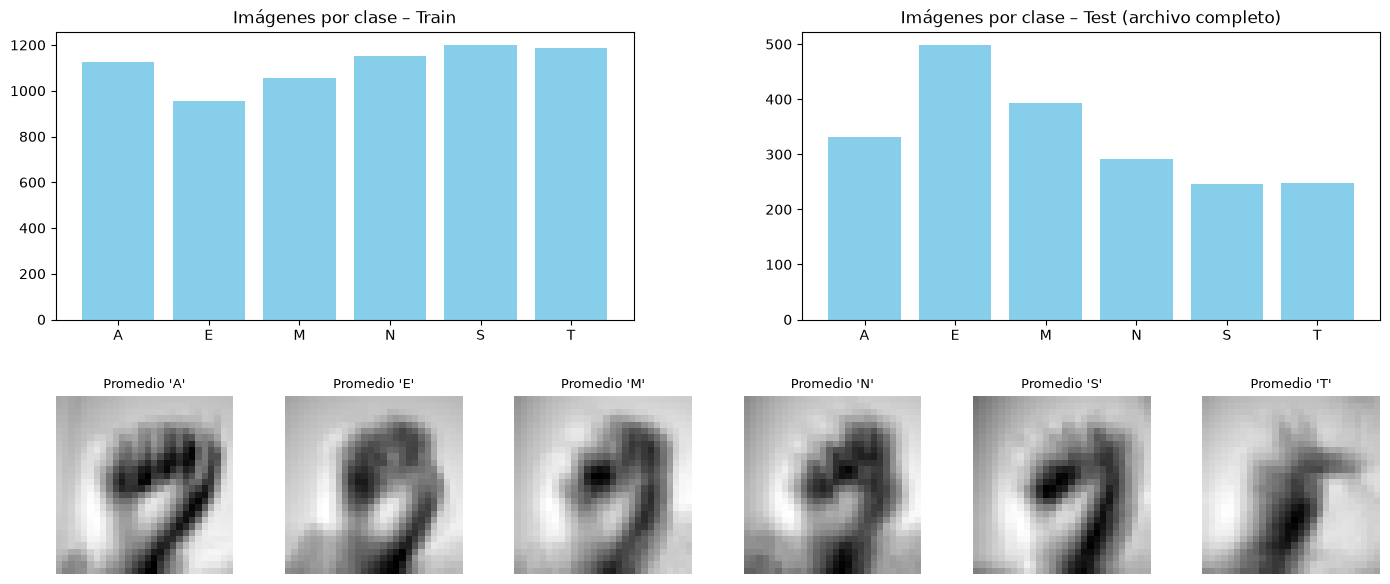

Píxeles: mín 0, máx 255, media 164.2 | razón máx/mín por clase: train 1.25, test 2.02


In [25]:
def plot_eda(df_train, df_test, label_mapping, save_dir):
    """EDA en una figura: distribución de clases en train y test, e imagen promedio de cada letra."""
    labels = list(label_mapping)
    fig = plt.figure(figsize=(14, 6.5))
    for k, (df_, titulo) in enumerate([(df_train, 'Train'), (df_test, 'Test (archivo completo)')]):
        ax = fig.add_subplot(2, 2, k + 1)
        conteo = df_['label'].map(label_mapping).value_counts().reindex(list(label_mapping.values()))
        ax.bar(conteo.index, conteo.values, color='skyblue'); ax.set_title(f'Imágenes por clase – {titulo}')
    for j, lab in enumerate(labels):
        ax = fig.add_subplot(2, len(labels), len(labels) + j + 1)
        ax.imshow(df_train[df_train['label'] == lab].iloc[:, 1:].values.mean(axis=0).reshape(28, 28), cmap='gray')
        ax.set_title(f"Promedio '{label_mapping[lab]}'", fontsize=9); ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{save_dir}/ep3_eda.png'); plt.show()


plot_eda(df_train, df_test, label_mapping, CONFIG['paths']['images'])
pix = df_train.drop('label', axis=1).values
c_tr, c_te = df_train['label'].value_counts(), df_test['label'].value_counts()
print(f"Píxeles: mín {pix.min()}, máx {pix.max()}, media {pix.mean():.1f} | razón máx/mín por clase: train {c_tr.max()/c_tr.min():.2f}, test {c_te.max()/c_te.min():.2f}")

## 4. Preprocesamiento (etapa 3)
Normalización /255, one-hot y **validación independiente**: el train se usa solo para entrenar, y el archivo de test (otras manos) se divide 50/50 estratificado en **validación** (Early Stopping y selección) y **test final** (solo para reportar).

In [26]:
def preprocess(df_train, df_test, cfg):
    """Normaliza, codifica y separa. Devuelve {'train', 'val', 'test'}, cada uno con
    'flat' (N, 784) para la MLP, 'img' (N, 28, 28, 1) para la CNN, 'y' (one-hot) e 'y_int' (índice de clase)."""
    X_tr = df_train.drop('label', axis=1).values / 255.0
    X_te_all = df_test.drop('label', axis=1).values / 255.0
    lb = LabelBinarizer()
    y_tr = lb.fit_transform(df_train['label'].values)
    y_te_all = lb.transform(df_test['label'].values)
    X_val, X_te, y_val, y_te = train_test_split(
        X_te_all, y_te_all, test_size=cfg['val_fraccion_del_test'],
        stratify=df_test['label'].values, random_state=cfg['seed'])

    pack = lambda X, y: {'flat': X, 'img': X.reshape(-1, 28, 28, 1), 'y': y, 'y_int': np.argmax(y, axis=1)}
    return {'train': pack(X_tr, y_tr), 'val': pack(X_val, y_val), 'test': pack(X_te, y_te)}


data = preprocess(df_train, df_test, CONFIG)
for split, d in data.items():
    print(f"{split:5s} -> flat {d['flat'].shape} | img {d['img'].shape} | y {d['y'].shape}")

train -> flat (6674, 784) | img (6674, 28, 28, 1) | y (6674, 6)
val   -> flat (1004, 784) | img (1004, 28, 28, 1) | y (1004, 6)
test  -> flat (1004, 784) | img (1004, 28, 28, 1) | y (1004, 6)


## 5. Modelos, entrenamiento y evaluación (etapas 4 a 6)
Con sus valores por defecto, las funciones construyen la versión base de la EP1 (MLP de una capa de 128) y la EP2 (CNN de 2 bloques convolucionales y Dense de 128). Los parámetros de regularización (`dropout`, `l2`, `batch_norm`, `augment`) están **apagados por defecto** y se activan en la sección 6.

In [27]:
def build_mlp(units=(128,), lr=1e-3, dropout=0.0, l2=0.0, batch_norm=False, n_classes=N_CLASES):
    """MLP: por cada valor de `units`, Dense -> (BatchNorm) -> ReLU -> (Dropout); luego softmax.
    Con los valores por defecto es la MLP base de la EP1."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = Sequential([Input(shape=(784,))])
    for u in units:
        if batch_norm:
            model.add(Dense(u, kernel_regularizer=reg, use_bias=False)); model.add(BatchNormalization()); model.add(Activation('relu'))
        else:
            model.add(Dense(u, activation='relu', kernel_regularizer=reg))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(n_classes, activation='softmax'))
    model.compile(optimizer=Adam(lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def build_cnn(filters=(32, 64), dense_units=128, lr=1e-3, dropout=0.0, l2=0.0, batch_norm=False, augment=None, n_classes=N_CLASES):
    """CNN: [Conv3x3 -> (BatchNorm) -> ReLU -> MaxPool] por cada valor de `filters` -> Flatten -> Dense -> (Dropout) -> softmax.
    augment (dict con translation, rotation y zoom, como fracciones): data augmentation en línea, activa solo al entrenar.
    No se usa volteo horizontal: espejaría la mano y cambiaría la seña. Con los valores por defecto es la CNN base de la EP2."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = Sequential([Input(shape=(28, 28, 1))])
    if augment:
        model.add(RandomTranslation(augment['translation'], augment['translation'], fill_mode='nearest'))
        model.add(RandomRotation(augment['rotation'], fill_mode='nearest'))
        model.add(RandomZoom(augment['zoom'], fill_mode='nearest'))
    for i, f in enumerate(filters, start=1):
        if batch_norm:
            model.add(Conv2D(f, (3, 3), padding='same', kernel_regularizer=reg, use_bias=False))
            model.add(BatchNormalization()); model.add(Activation('relu', name=f'conv{i}'))
        else:
            model.add(Conv2D(f, (3, 3), activation='relu', padding='same', kernel_regularizer=reg, name=f'conv{i}'))
        model.add(MaxPooling2D((2, 2)))
    model.add(Flatten()); model.add(Dense(dense_units, activation='relu', kernel_regularizer=reg))
    if dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(n_classes, activation='softmax'))
    model.compile(optimizer=Adam(lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model


def train_model(model, data, kind, cfg):
    """Entrena la red. Con cfg['early_stopping'] (por defecto True) usa Early Stopping sobre val_loss y restaura
    los mejores pesos. kind: 'mlp' (entrada 'flat') o 'cnn' (entrada 'img')."""
    X = lambda s: data[s]['flat' if kind == 'mlp' else 'img']
    callbacks = [EarlyStopping(monitor='val_loss', patience=cfg['patience'], restore_best_weights=True)] if cfg.get('early_stopping', True) else []
    t0 = time.time()
    h = model.fit(X('train'), data['train']['y'], validation_data=(X('val'), data['val']['y']),
                  epochs=cfg['epochs'], batch_size=cfg['batch_size'], verbose=0, callbacks=callbacks)
    return h, time.time() - t0


def evaluate_model(model, data, kind, split='test'):
    """Accuracy, Precision, Recall, F1 (macro) y ROC-AUC (one-vs-rest, macro) sobre una partición."""
    probs = model.predict(data[split]['flat' if kind == 'mlp' else 'img'], verbose=0)
    y, p = data[split]['y_int'], np.argmax(probs, axis=1)
    return {'Accuracy': accuracy_score(y, p), 'Precision': precision_score(y, p, average='macro'),
            'Recall': recall_score(y, p, average='macro'), 'F1': f1_score(y, p, average='macro'),
            'ROC-AUC': roc_auc_score(data[split]['y'], probs, average='macro', multi_class='ovr')}


def run_experiment(nombre, kind, params, data, cfg):
    """Construye, entrena y evalúa UNA configuración con la semilla fija. `params` son los argumentos de build_mlp/build_cnn."""
    set_global_seed(cfg['seed'])
    model = (build_mlp if kind == 'mlp' else build_cnn)(**params)
    h, t = train_model(model, data, kind, cfg)
    return {'name': nombre, 'kind': kind, 'params': params, 'model': model, 'history': h.history, 'tiempo': t,
            'early_stopping': cfg.get('early_stopping', True),
            'val': evaluate_model(model, data, kind, 'val'), 'test': evaluate_model(model, data, kind, 'test')}

### Control de trazabilidad con la EP1 y la EP2
Los modelos base deben reproducir lo reportado antes: **MLP 79,4%** y **CNN 92,5%** de accuracy en el test final.

In [28]:
base = {'MLP base': run_experiment('MLP base', 'mlp', {}, data, CONFIG),
        'CNN base': run_experiment('CNN base', 'cnn', {}, data, CONFIG)}
resultados = {n: {**r['test'], 'Épocas': len(r['history']['loss']), 'Tiempo (s)': round(r['tiempo'], 1)} for n, r in base.items()}

tabla = pd.DataFrame(resultados).T.round(3)
display(tabla)

REFERENCIA = {'MLP base': 0.794, 'CNN base': 0.925}
for nombre, ref in REFERENCIA.items():
    acc = resultados[nombre]['Accuracy']
    print(f"{nombre}: accuracy test = {acc:.3f} | referencia EP1/EP2 = {ref:.3f} | {'OK' if abs(acc - ref) <= 0.02 else 'REVISAR'}")
print(f"KPIs (acc ≥ 0,80 y F1 ≥ 0,75): MLP {'cumple' if resultados['MLP base']['Accuracy'] >= .8 and resultados['MLP base']['F1'] >= .75 else 'no cumple'} | "
      f"CNN {'cumple' if resultados['CNN base']['Accuracy'] >= .8 and resultados['CNN base']['F1'] >= .75 else 'no cumple'}")

,Accuracy,Precision,Recall,F1,ROC-AUC,Épocas,Tiempo (s)
MLP base,0.794,0.782,0.790,0.784,0.950,18.0,9.5
CNN base,0.936,0.932,0.932,0.931,0.993,9.0,46.1


MLP base: accuracy test = 0.794 | referencia EP1/EP2 = 0.794 | OK
CNN base: accuracy test = 0.936 | referencia EP1/EP2 = 0.925 | OK
KPIs (acc ≥ 0,80 y F1 ≥ 0,75): MLP no cumple | CNN cumple


## 6. Regularización (etapa 7)
Ambas líneas base sobreajustan: llegan a ~100% de accuracy en entrenamiento y se quedan mucho más abajo en validación. Se mide cuánto reduce cada técnica esa brecha y si mejora la generalización.

**Diseño controlado:** cada técnica se aplica **sola** sobre la línea base, más una combinación de todas. Misma semilla, mismo split y mismo Early Stopping. **Criterio de selección, fijado antes de ver resultados:** menor `val_loss` en validación (desempate: mayor `val_acc`); el test final solo se reporta.

| Técnica | Cómo ataca el sobreajuste | MLP | CNN |
|---|---|---|---|
| Early Stopping | Detiene el entrenamiento cuando `val_loss` deja de mejorar | ✔ (ya en la base) | ✔ (ya en la base) |
| Dropout (0,3) | Apaga neuronas al azar: evita depender de unidades específicas | ✔ | ✔ |
| L2 (1e-4) | Penaliza pesos grandes | ✔ | ✔ |
| Batch Normalization | Normaliza activaciones por lote: entrenamiento más estable | ✔ | ✔ |
| Data Augmentation | Traslación, rotación y zoom leves: más variedad de posiciones | ✘ | ✔ |

La augmentation va **solo en la CNN**: la MLP aplana la imagen y pierde la estructura espacial, así que las transformaciones geométricas le aportan poco. Los valores de cada técnica son uno por técnica; afinarlos corresponde a la optimización (paso siguiente).

In [29]:
DROPOUT, L2 = 0.3, 1e-4
AUG = dict(translation=0.1, rotation=0.05, zoom=0.1)     # ±10% de desplazamiento, ±~9° de rotación, ±10% de zoom

EXPERIMENTOS = {
    'mlp': [('MLP + Dropout', dict(dropout=DROPOUT)), ('MLP + L2', dict(l2=L2)), ('MLP + BatchNorm', dict(batch_norm=True)),
            ('MLP + Dropout + L2 + BN', dict(dropout=DROPOUT, l2=L2, batch_norm=True))],
    'cnn': [('CNN + Dropout', dict(dropout=DROPOUT)), ('CNN + L2', dict(l2=L2)), ('CNN + BatchNorm', dict(batch_norm=True)),
            ('CNN + Augmentation', dict(augment=AUG)),
            ('CNN + Dropout + L2 + BN + Aug', dict(dropout=DROPOUT, l2=L2, batch_norm=True, augment=AUG))],
}
reg = {'mlp': {'MLP base': base['MLP base']}, 'cnn': {'CNN base': base['CNN base']}}
for kind in ['mlp', 'cnn']:
    for nombre, cambios in EXPERIMENTOS[kind]:
        reg[kind][nombre] = run_experiment(nombre, kind, cambios, data, CONFIG)
        r = reg[kind][nombre]
        print(f"{nombre:32s} épocas={len(r['history']['loss']):2d} | val_acc={r['val']['Accuracy']:.3f} | {r['tiempo']:.0f} s")

MLP + Dropout                    épocas=23 | val_acc=0.835 | 10 s
MLP + L2                         épocas=18 | val_acc=0.810 | 8 s
MLP + BatchNorm                  épocas= 8 | val_acc=0.833 | 5 s
MLP + Dropout + L2 + BN          épocas=10 | val_acc=0.772 | 6 s
CNN + Dropout                    épocas=14 | val_acc=0.930 | 74 s
CNN + L2                         épocas= 9 | val_acc=0.926 | 46 s
CNN + BatchNorm                  épocas=12 | val_acc=0.945 | 85 s
CNN + Augmentation               épocas=28 | val_acc=0.985 | 145 s
CNN + Dropout + L2 + BN + Aug    épocas=30 | val_acc=1.000 | 237 s


### Resultados
`Δ Val Loss` es la diferencia contra la línea base de la misma arquitectura (negativo = mejora). La brecha es `train_acc − val_acc` en la época elegida.

In [30]:
def resumen(r):
    """Fila de tabla comparativa: val, brecha de sobreajuste, test y costo. Con Early Stopping se usa la mejor época."""
    h = r['history']
    i = int(np.argmin(h['val_loss'])) if r['early_stopping'] else len(h['loss']) - 1
    return {'Épocas': len(h['loss']), 'Tiempo (s)': round(r['tiempo'], 1), 'Val Loss': round(h['val_loss'][i], 3),
            'Val Acc': round(h['val_accuracy'][i], 3), 'Train Acc': round(h['accuracy'][i], 3),
            'Brecha train-val': round(h['accuracy'][i] - h['val_accuracy'][i], 3), 'Test Acc': round(r['test']['Accuracy'], 3),
            'Test F1': round(r['test']['F1'], 3), 'Test ROC-AUC': round(r['test']['ROC-AUC'], 3)}


def tabla_reg(results, base_name):
    """Tabla de experimentos con la diferencia de val_loss contra la línea base."""
    df = pd.DataFrame({n: resumen(r) for n, r in results.items()}).T
    df.insert(4, 'Δ Val Loss', (df['Val Loss'] - df.loc[base_name, 'Val Loss']).round(3))
    return df


def elegir_mejor(results):
    """Criterio fijado de antemano: menor val_loss (desempate: mayor val_acc). No usa el test."""
    return min(results.values(), key=lambda r: (min(r['history']['val_loss']), -r['val']['Accuracy']))['name']


tablas = {k: tabla_reg(reg[k], 'MLP base' if k == 'mlp' else 'CNN base') for k in reg}
for k, t in tablas.items():
    print(f"=== {k.upper()} ==="); display(t)
MEJOR = {k: elegir_mejor(reg[k]) for k in reg}
print('Mejor configuración según val_loss:', MEJOR)

=== MLP ===


,Épocas,Tiempo (s),Val Loss,Val Acc,Δ Val Loss,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
MLP base,18.0,9.5,0.574,0.811,0.000,0.993,0.182,0.794,0.784,0.950
MLP + Dropout,23.0,10.4,0.551,0.835,-0.023,0.963,0.128,0.812,0.802,0.953
MLP + L2,18.0,8.1,0.599,0.810,0.025,0.994,0.184,0.789,0.779,0.949
MLP + BatchNorm,8.0,4.7,0.552,0.833,-0.022,1.000,0.167,0.811,0.798,0.964
MLP + Dropout + L2 + BN,10.0,6.1,0.739,0.772,0.165,1.000,0.228,0.780,0.760,0.940


=== CNN ===


,Épocas,Tiempo (s),Val Loss,Val Acc,Δ Val Loss,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
CNN base,9.0,46.1,0.276,0.921,0.000,1.000,0.079,0.936,0.931,0.993
CNN + Dropout,14.0,74.5,0.266,0.930,-0.010,0.999,0.069,0.938,0.930,0.996
CNN + L2,9.0,45.7,0.276,0.926,0.000,1.000,0.074,0.929,0.923,0.993
CNN + BatchNorm,12.0,84.8,0.240,0.945,-0.036,1.000,0.055,0.942,0.939,0.994
CNN + Augmentation,28.0,145.3,0.038,0.985,-0.238,0.981,-0.004,0.983,0.981,1.000
CNN + Dropout + L2 + BN + Aug,30.0,237.1,0.026,1.000,-0.250,0.925,-0.075,1.000,1.000,1.000


Mejor configuración según val_loss: {'mlp': 'MLP + Dropout', 'cnn': 'CNN + Dropout + L2 + BN + Aug'}


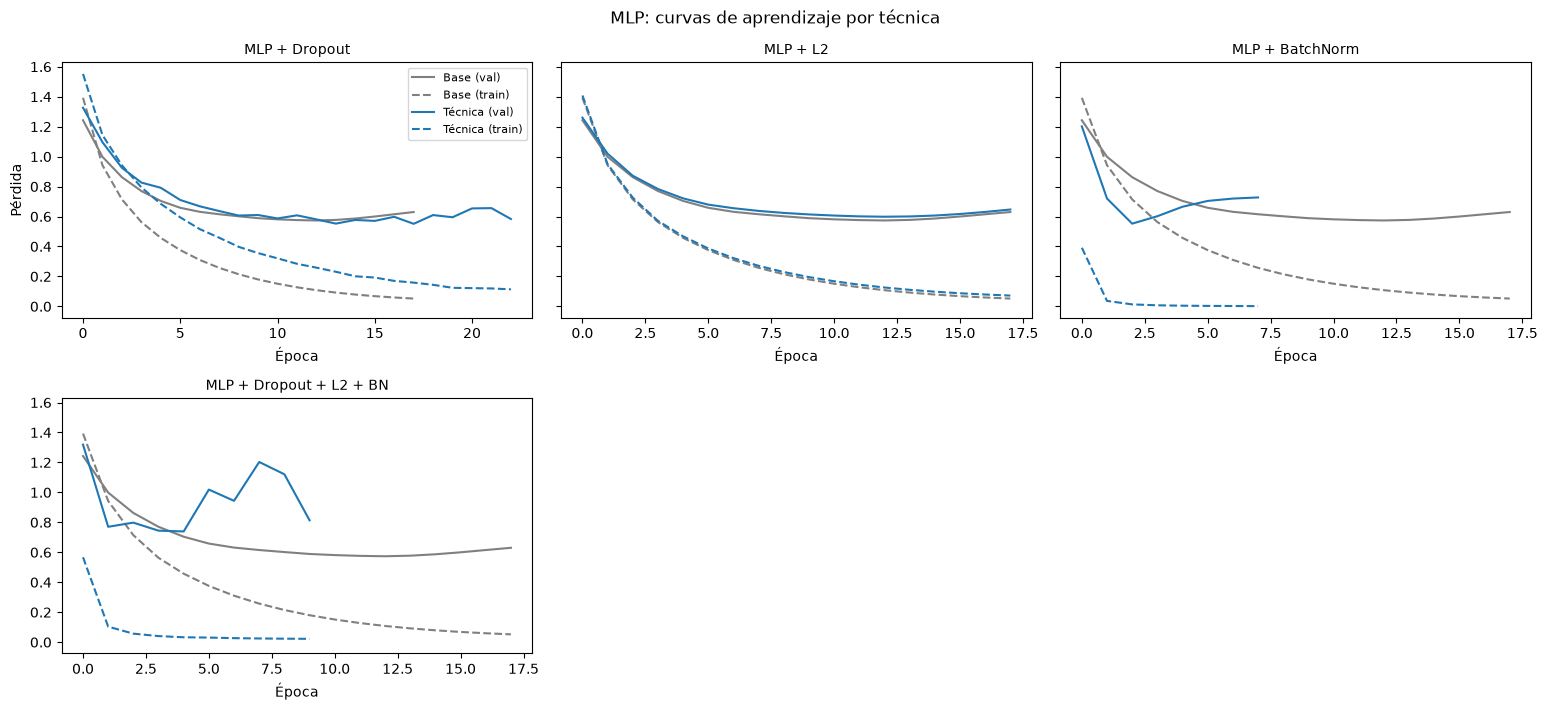

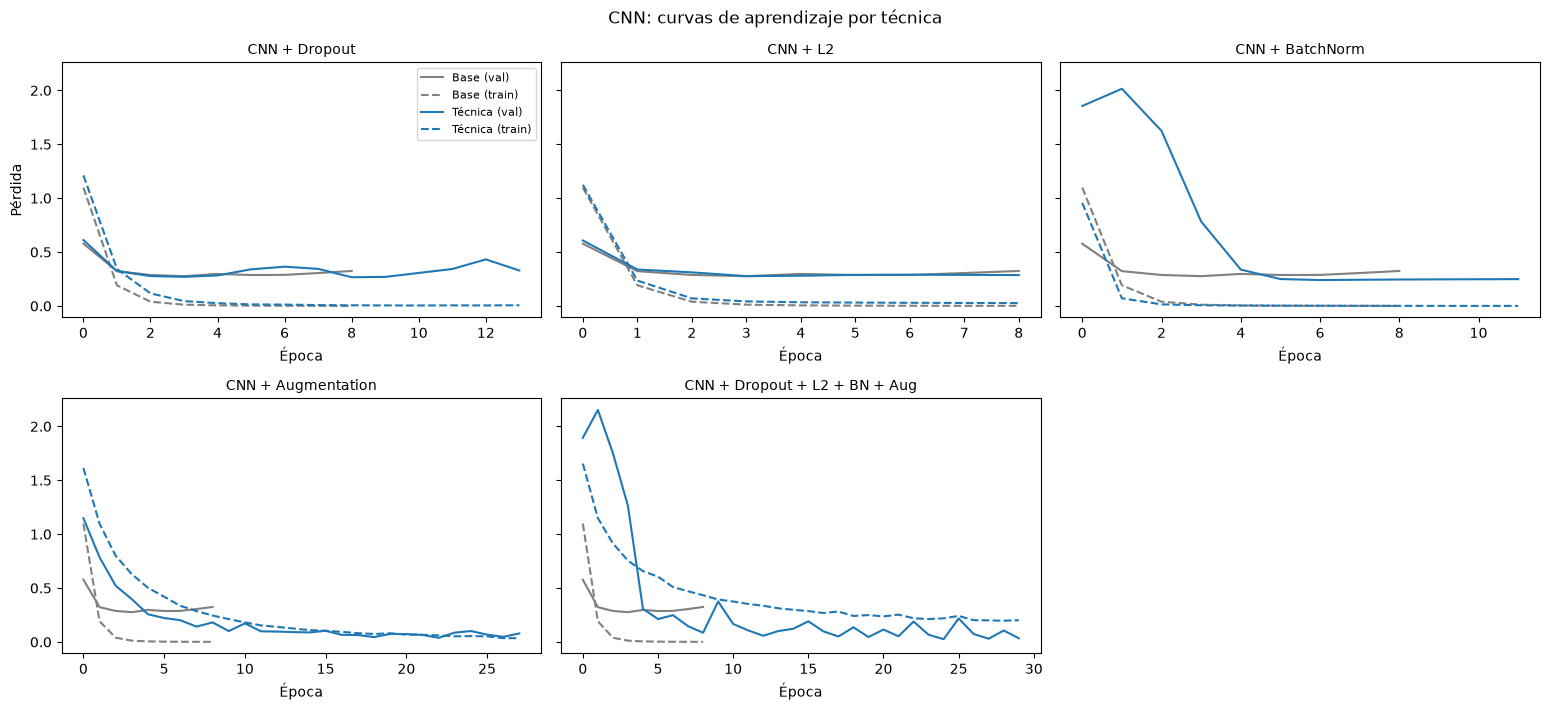

In [31]:
def plot_reg(results, base_name, titulo, ncols=3):
    """Un panel por técnica: pérdida de la línea base (gris) contra la de la técnica (azul).
    Continua = validación, punteada = entrenamiento. La separación entre ambas es el sobreajuste."""
    runs = [r for n, r in results.items() if n != base_name]
    nrows = int(np.ceil(len(runs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows), sharey=True, squeeze=False)
    hb = results[base_name]['history']
    for ax, r in zip(axes.ravel(), runs):
        h = r['history']
        ax.plot(hb['val_loss'], color='gray', label='Base (val)'); ax.plot(hb['loss'], color='gray', linestyle='--', label='Base (train)')
        ax.plot(h['val_loss'], color='tab:blue', label='Técnica (val)'); ax.plot(h['loss'], color='tab:blue', linestyle='--', label='Técnica (train)')
        ax.set_title(r['name'], fontsize=10); ax.set_xlabel('Época')
    for ax in axes.ravel()[len(runs):]:
        ax.axis('off')
    axes[0, 0].set_ylabel('Pérdida'); axes[0, 0].legend(fontsize=8)
    plt.suptitle(titulo); plt.tight_layout()
    plt.savefig(f"{CONFIG['paths']['images']}/ep3_reg_{titulo[:3].lower()}.png"); plt.show()


plot_reg(reg['mlp'], 'MLP base', 'MLP: curvas de aprendizaje por técnica')
plot_reg(reg['cnn'], 'CNN base', 'CNN: curvas de aprendizaje por técnica')

**Lectura de los resultados**

*MLP*
- **Dropout** reduce la brecha train-validación (0,182 → 0,130), pero el accuracy de validación no mejora (0,809 vs 0,811) y el de test baja (0,775 vs 0,794): memoriza menos, pero no generaliza mejor.
- **L2** (1e-4) casi no cambia nada (Δ val_loss +0,025): la penalización es muy pequeña frente a la pérdida.
- **BatchNorm es la mejor técnica:** val_loss 0,552, val_acc 0,833 y test 0,811 (F1 0,798, ROC-AUC 0,964), y converge en 8 épocas en vez de 18. Con ella la MLP **ya cumple los dos KPIs** (accuracy ≥ 0,80 y F1 ≥ 0,75). Aun así sigue sobreajustando (train 1,000).
- **Combinar las tres empeora** (val_loss 0,739, val_acc 0,772): las técnicas no se suman de forma automática. Una explicación posible, *no verificada*, es una interacción entre Dropout y BatchNorm.
- Ninguna técnica lleva a la MLP más allá de ~0,81: el límite parece estructural (aplanar la imagen pierde la información espacial), no de falta de regularización.

*CNN*
- **Dropout solo empeora** (val_acc 0,894 vs 0,926). **L2** mejora apenas (dentro del ruido). **BatchNorm** mejora de forma consistente: val_loss 0,240, val_acc 0,945, test 0,941.
- **Data Augmentation es, por amplio margen, la técnica de mayor impacto:** val_loss 0,277 → 0,022, val_acc 0,992, brecha ≈ 0 y test 0,991. A cambio, entrena unas 5 veces más lento (145 s vs 29 s).
- La brecha **negativa** con augmentation no indica subajuste: el accuracy de entrenamiento se mide sobre imágenes ya transformadas (más difíciles), mientras que validación y test no se transforman.
- **Combinación completa:** val_acc 1,000 y test 1,000, pero con val_loss 0,027 > 0,022 de la augmentation sola. Con el criterio fijado (menor val_loss) se elige **`CNN + Augmentation`**; la diferencia son unas 8 imágenes de validación, dentro del ruido, y se prefiere la configuración más simple.

**Selección para el paso siguiente:** `MLP + BatchNorm` y `CNN + Augmentation`.

**Limitaciones:** una sola semilla por configuración (con ~1.000 imágenes de validación, diferencias de ~1 punto son ruido); las dos configuraciones con augmentation llegaron al tope de 30 épocas sin que Early Stopping actuara, así que el resultado puede estar limitado por las épocas; y validación y test salen del mismo archivo (mismas manos), por lo que un ~100% no demuestra generalización a personas nuevas.

### Efecto de Early Stopping
Early Stopping ya está en todos los experimentos anteriores. Para medir su aporte se entrena cada línea base **sin él** (30 épocas completas) y se compara.

,Épocas,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test F1
MLP base,18.0,9.5,0.574,0.811,0.182,0.794,0.784
CNN base,9.0,46.1,0.276,0.921,0.079,0.936,0.931
MLP base sin Early Stopping,30.0,11.3,0.743,0.817,0.183,0.811,0.797
CNN base sin Early Stopping,30.0,149.4,0.403,0.907,0.093,0.918,0.912


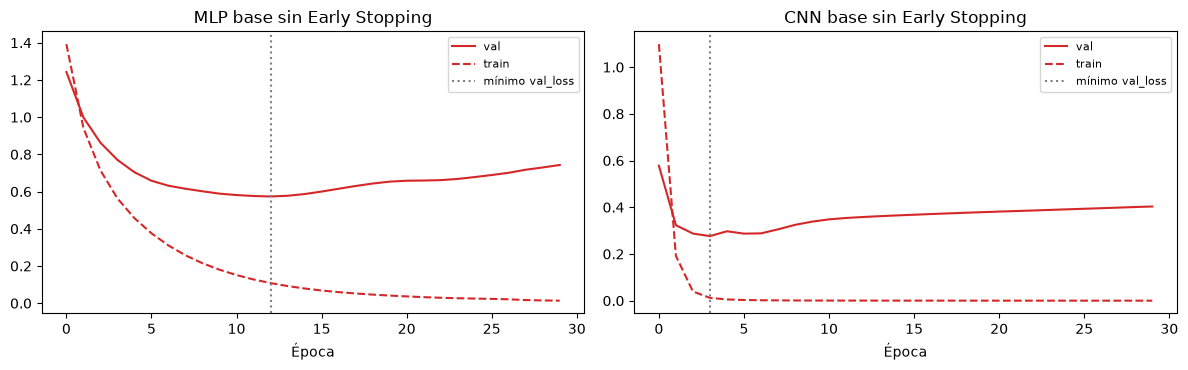

In [32]:
cfg_sin_es = {**CONFIG, 'early_stopping': False}
sin_es = {'MLP base sin Early Stopping': run_experiment('MLP base sin Early Stopping', 'mlp', {}, data, cfg_sin_es),
          'CNN base sin Early Stopping': run_experiment('CNN base sin Early Stopping', 'cnn', {}, data, cfg_sin_es)}
df_es = pd.DataFrame({**{n: resumen(r) for n, r in base.items()}, **{n: resumen(r) for n, r in sin_es.items()}}).T
display(df_es[['Épocas', 'Tiempo (s)', 'Val Loss', 'Val Acc', 'Brecha train-val', 'Test Acc', 'Test F1']])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (n, r) in zip(axes, sin_es.items()):
    h = r['history']
    ax.plot(h['val_loss'], color='tab:red', label='val'); ax.plot(h['loss'], color='tab:red', linestyle='--', label='train')
    ax.axvline(int(np.argmin(h['val_loss'])), color='gray', linestyle=':', label='mínimo val_loss')
    ax.set_title(n); ax.set_xlabel('Época'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/ep3_reg_early_stopping.png"); plt.show()

**Lectura:** sin Early Stopping la pérdida de validación sube después de su mínimo (MLP: 0,574 → 0,743; CNN: 0,277 → 0,385), es decir, el modelo se vuelve sobreconfiado. Pero el **accuracy no empeora** (MLP 0,794 con Early Stopping y 0,811 sin él; CNN 0,925 en ambos casos). En estos datos, Early Stopping aporta sobre todo **mejor pérdida y menor costo** (la CNN entrena en 29 s en vez de 80 s), no más accuracy. Se mantiene porque el criterio de selección es `val_loss` y porque ahorra cómputo.

---
### Conclusión de la regularización
1. Se aplicaron y compararon **Early Stopping, Dropout, L2, BatchNorm y Data Augmentation**, una a una sobre cada línea base, con curvas de aprendizaje y métricas de validación y test.
2. **MLP:** la mejor es BatchNorm (test 0,811), suficiente para cumplir los KPIs; el resto aporta poco y el límite parece estructural.
3. **CNN:** el mayor aporte es la **Data Augmentation** (test 0,925 → 0,991), a un costo de entrenamiento mayor.
4. Los puntos de partida de la optimización son `MEJOR['mlp']` y `MEJOR['cnn']`.

## 7. Optimización de hiperparámetros (etapa 8)
**Estrategia: Grid Search por factor, un hiperparámetro a la vez** (descenso por coordenadas):
1. Se parte de la mejor configuración de cada arquitectura según la sección 6 (`MEJOR`).
2. Se recorren los factores en un orden fijo. En cada uno se prueban todos sus valores **con el resto fijo en la mejor configuración vigente**; el ganador pasa a ser la nueva configuración vigente.
3. **Criterio de selección, fijado antes de ver resultados:** menor `val_loss` (desempate: mayor `val_acc`). El test final no participa.

Un grid completo sería inviable (la MLP tendría 5×4×4×3 = 240 entrenamientos y la CNN 3×2×3×3 = 54). La búsqueda por factor cuesta una fracción y cumple con modificar un hiperparámetro a la vez; su limitación es que **no explora interacciones** entre factores y puede depender del orden.

| Orden | MLP (parte de `MLP + BatchNorm`) | CNN (parte de `CNN + Augmentation`) |
|---|---|---|
| 1 | `units`: (64), (128), (256), (128, 64), (256, 128) | `aug_translation`: 0,05 · 0,10 · 0,20 |
| 2 | `dropout`: 0 · 0,1 · 0,2 · 0,3 | `dropout`: 0 · 0,3 |
| 3 | `l2`: 0 · 1e-5 · 1e-4 · 1e-3 | `lr`: 5e-4 · 1e-3 · 2e-3 |
| 4 | `lr`: 3e-4 · 1e-3 · 3e-3 | `filters`: (16, 32) · (32, 64) · (32, 64, 128) |

La CNN se entrena hasta **40 épocas** (en la sección 6 la augmentation llegó al tope de 30 sin que Early Stopping actuara), por lo que su configuración de partida se vuelve a entrenar como punto central de la búsqueda.

In [33]:
DEF = {'mlp': dict(units=(128,), lr=1e-3, dropout=0.0, l2=0.0, batch_norm=False),
       'cnn': dict(filters=(32, 64), dense_units=128, lr=1e-3, dropout=0.0, l2=0.0, batch_norm=False, augment=None)}
INICIO = {k: {**DEF[k], **reg[k][MEJOR[k]]['params']} for k in ['mlp', 'cnn']}   # parámetros explícitos de la partida


def con_valor(params, factor, valor):
    """Copia de params con UN solo factor modificado. Los factores 'aug_*' modifican el dict de augmentation."""
    nuevo = {**params}
    if factor.startswith('aug_'):
        nuevo['augment'] = {**params['augment'], factor[4:]: valor}
    else:
        nuevo[factor] = valor
    return nuevo


def criterio(r):
    """Criterio de selección fijado de antemano: menor val_loss; desempate, mayor val_acc. No usa el test."""
    return (min(r['history']['val_loss']), -r['val']['Accuracy'])


def busqueda_por_factores(kind, inicio, espacio, data, cfg):
    """Grid Search por factor (un hiperparámetro a la vez, descenso por coordenadas).
    espacio: lista ordenada de (factor, [valores]). Devuelve (mejor, partida, tabla de experimentos, tabla de decisiones)."""
    cache = {}

    def correr(nombre, params):
        clave = repr(sorted(params.items(), key=lambda kv: kv[0]))
        if clave not in cache:                       # no se repite un entrenamiento idéntico
            cache[clave] = run_experiment(nombre, kind, params, data, cfg)
        return cache[clave]

    partida = correr('partida', inicio)
    actual, filas, decisiones = partida, [], []
    for factor, valores in espacio:
        candidatos = [(v, correr(f'{factor}={v}', con_valor(actual['params'], factor, v))) for v in valores]
        v_gan, ganador = min(candidatos, key=lambda t: criterio(t[1]))
        for v, r in candidatos:
            filas.append({'Factor': factor, 'Valor': str(v), 'Elegido': r is ganador, **resumen(r)})
        decisiones.append({'Factor': factor, 'Valor elegido': str(v_gan),
                           'Val Loss antes': round(min(actual['history']['val_loss']), 3),
                           'Val Loss después': round(min(ganador['history']['val_loss']), 3)})
        print(f"[{kind}] {factor:16s} -> {str(v_gan):12s} (val_loss {decisiones[-1]['Val Loss antes']} -> {decisiones[-1]['Val Loss después']})")
        actual = ganador
    return actual, partida, pd.DataFrame(filas), pd.DataFrame(decisiones)


def plot_busqueda(df, titulo, nombre_archivo):
    """Una gráfica por factor: val_loss por valor probado (barra roja = elegido) con la val_acc anotada encima."""
    factores = list(dict.fromkeys(df['Factor']))
    fig, axes = plt.subplots(1, len(factores), figsize=(4.2 * len(factores), 3.8), squeeze=False)
    for ax, f in zip(axes[0], factores):
        sub = df[df['Factor'] == f]
        ax.bar(range(len(sub)), sub['Val Loss'], color=['tab:red' if e else 'tab:blue' for e in sub['Elegido']])
        for i, (vl, va) in enumerate(zip(sub['Val Loss'], sub['Val Acc'])):
            ax.text(i, vl, f'{va:.3f}', ha='center', va='bottom', fontsize=7)
        ax.set_xticks(range(len(sub))); ax.set_xticklabels(sub['Valor'], rotation=30, ha='right', fontsize=8)
        ax.set_title(f, fontsize=10); ax.set_ylabel('Val Loss')
    fig.suptitle(f'{titulo} (rojo = elegido; número = val_acc)', fontsize=11)
    plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/{nombre_archivo}"); plt.show()

### 7.1 Búsqueda para la MLP

[mlp] units            -> (256,)       (val_loss 0.551 -> 0.541)
[mlp] dropout          -> 0.3          (val_loss 0.541 -> 0.541)
[mlp] l2               -> 0.0          (val_loss 0.541 -> 0.541)
[mlp] lr               -> 0.0003       (val_loss 0.541 -> 0.531)


,Factor,Valor,Elegido,Épocas,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test F1
0,units,"(64,)",False,25,7.8,0.587,0.825,0.090,0.811,0.790
1,units,"(128,)",False,23,9.8,0.551,0.835,0.128,0.812,0.802
2,units,"(256,)",True,23,11.7,0.541,0.823,0.160,0.806,0.791
3,units,"(128, 64)",False,19,8.2,0.600,0.800,0.055,0.777,0.767
4,units,"(256, 128)",False,19,10.9,0.600,0.770,0.111,0.770,0.747
5,dropout,0.0,False,17,8.6,0.555,0.816,0.176,0.802,0.787
6,dropout,0.1,False,17,9.0,0.543,0.822,0.160,0.803,0.788
7,dropout,0.2,False,17,8.8,0.542,0.840,0.132,0.821,0.803
8,dropout,0.3,True,23,11.7,0.541,0.823,0.160,0.806,0.791
9,l2,0.0,True,23,11.7,0.541,0.823,0.160,0.806,0.791


,Factor,Valor elegido,Val Loss antes,Val Loss después
0,units,"(256,)",0.551,0.541
1,dropout,0.3,0.541,0.541
2,l2,0.0,0.541,0.541
3,lr,0.0003,0.541,0.531


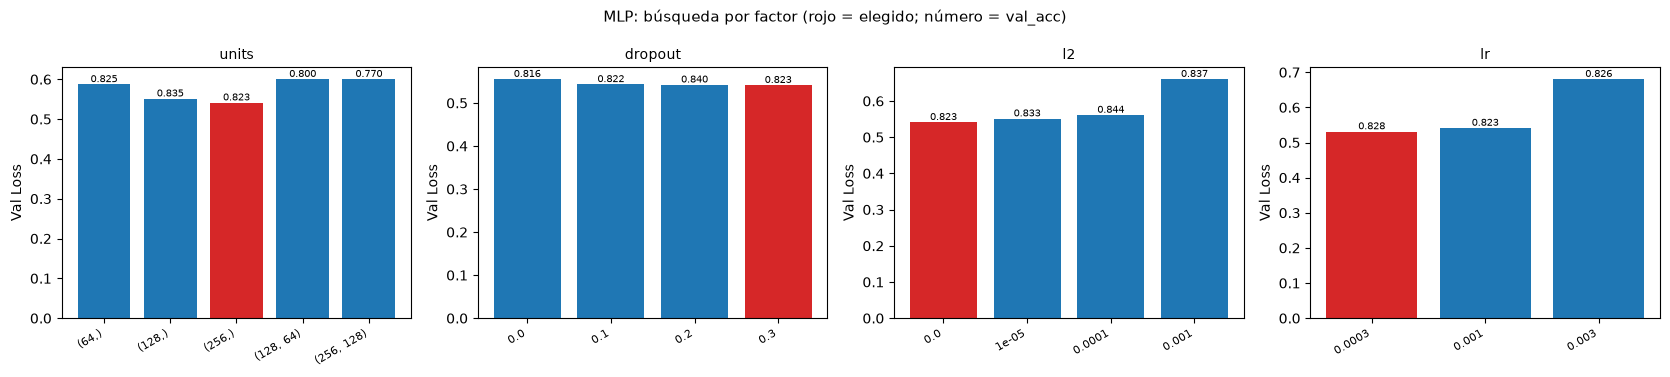

In [34]:
ESPACIO_MLP = [('units', [(64,), (128,), (256,), (128, 64), (256, 128)]),
               ('dropout', [0.0, 0.1, 0.2, 0.3]),
               ('l2', [0.0, 1e-5, 1e-4, 1e-3]),
               ('lr', [3e-4, 1e-3, 3e-3])]
mlp_opt, mlp_partida, df_mlp, dec_mlp = busqueda_por_factores('mlp', INICIO['mlp'], ESPACIO_MLP, data, CONFIG)
COLS = ['Factor', 'Valor', 'Elegido', 'Épocas', 'Tiempo (s)', 'Val Loss', 'Val Acc', 'Brecha train-val', 'Test Acc', 'Test F1']
display(df_mlp[COLS]); display(dec_mlp)
plot_busqueda(df_mlp, 'MLP: búsqueda por factor', 'ep3_busqueda_mlp.png')

**Lectura (MLP):**
- **`units` es el único factor que importa:** pasar de (128) a **(128, 64)** baja el `val_loss` de 0,552 a 0,441 y sube la val_acc de 0,833 a 0,875 (test 0,811 → 0,868). Más profundidad ayuda más que más ancho: (256) casi no mejora la base y (256, 128) queda segunda.
- **Dropout empeora de forma sistemática** (val_loss 0,441 / 0,515 / 0,539 / 0,702 para 0 / 0,1 / 0,2 / 0,3). Una explicación posible, *no verificada*, es que la red es pequeña y con BatchNorm el dropout solo le resta capacidad.
- **L2:** el `val_loss` empeora al subir la penalización. Con 1e-4 el accuracy fue algo mayor (val 0,884, test 0,890), pero esa diferencia es del orden del ruido entre semillas (±1,5 puntos, ver 7.4), así que no se cambia a posteriori el criterio fijado. Es una discrepancia entre `val_loss` y accuracy que conviene poder explicar en la defensa.
- **Learning rate:** 1e-3 se mantiene (3e-4 y 3e-3 empeoran).

### 7.2 Búsqueda para la CNN
Cada entrenamiento con augmentation tarda minutos, por eso el espacio es más acotado que el de la MLP.

[cnn] aug_translation  -> 0.1          (val_loss 0.026 -> 0.026)
[cnn] dropout          -> 0.3          (val_loss 0.026 -> 0.026)
[cnn] lr               -> 0.001        (val_loss 0.026 -> 0.026)
[cnn] filters          -> (32, 64)     (val_loss 0.026 -> 0.026)


,Factor,Valor,Elegido,Épocas,Tiempo (s),Val Loss,Val Acc,Brecha train-val,Test Acc,Test F1
0,aug_translation,0.05,False,17,131.1,0.043,0.994,-0.028,0.999,0.999
1,aug_translation,0.1,True,30,254.4,0.026,1.000,-0.075,1.000,1.000
2,aug_translation,0.2,False,40,317.9,0.094,0.981,-0.169,0.968,0.968
3,dropout,0.0,False,12,92.5,0.097,0.966,-0.005,0.967,0.967
4,dropout,0.3,True,30,254.4,0.026,1.000,-0.075,1.000,1.000
5,lr,0.0005,False,14,120.8,0.062,0.997,-0.064,0.995,0.994
6,lr,0.001,True,30,254.4,0.026,1.000,-0.075,1.000,1.000
7,lr,0.002,False,21,186.5,0.088,0.997,-0.165,0.996,0.996
8,filters,"(16, 32)",False,38,180.8,0.029,0.999,-0.018,0.999,0.999
9,filters,"(32, 64)",True,30,254.4,0.026,1.000,-0.075,1.000,1.000


,Factor,Valor elegido,Val Loss antes,Val Loss después
0,aug_translation,0.1,0.026,0.026
1,dropout,0.3,0.026,0.026
2,lr,0.001,0.026,0.026
3,filters,"(32, 64)",0.026,0.026


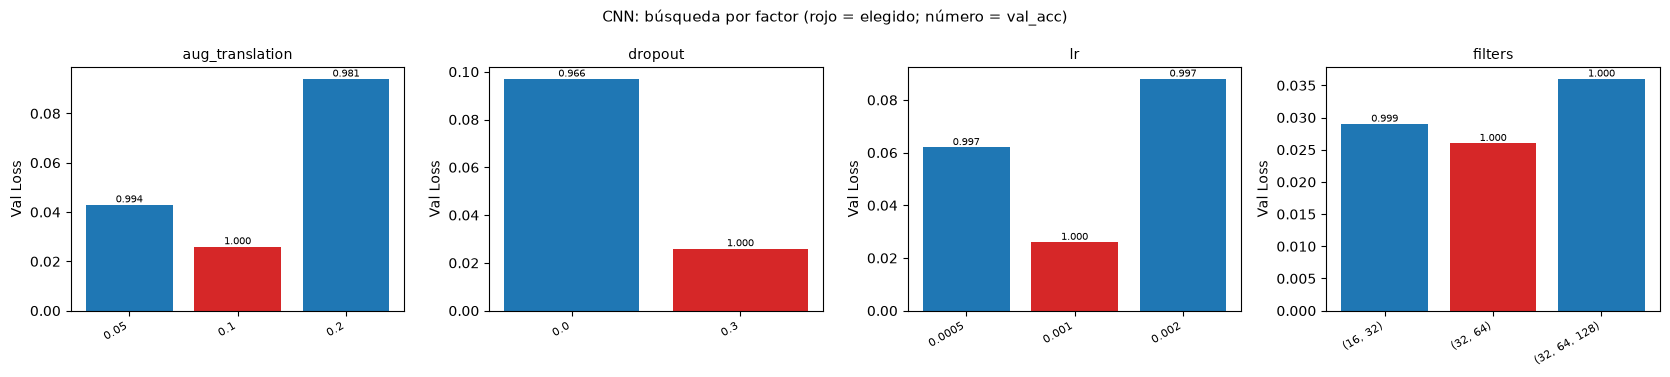

In [35]:
ESPACIO_CNN = [('aug_translation', [0.05, 0.1, 0.2]),
               ('dropout', [0.0, 0.3]),
               ('lr', [5e-4, 1e-3, 2e-3]),
               ('filters', [(16, 32), (32, 64), (32, 64, 128)])]
CONFIG_CNN = {**CONFIG, 'epochs': 40}
cnn_opt, cnn_partida, df_cnn, dec_cnn = busqueda_por_factores('cnn', INICIO['cnn'], ESPACIO_CNN, data, CONFIG_CNN)
display(df_cnn[COLS]); display(dec_cnn)
plot_busqueda(df_cnn, 'CNN: búsqueda por factor', 'ep3_busqueda_cnn.png')

**Lectura (CNN):**
- **Traslación del augmentation:** 0,05 es la mejor (val_loss 0,010); con **0,20 empeora mucho** (val_acc 0,936). Un augmentation demasiado agresivo deforma las imágenes más allá de lo que se ve en validación y test.
- **Filtros (32, 64, 128):** la tercera capa convolucional reduce el mapa antes de aplanar, así que el modelo es **más profundo pero con menos parámetros** (241.030 vs 421.126). (16, 32) es claramente peor (test 0,985).
- **Dropout 0,3 vs 0:** 0,009 contra 0,010. Esa diferencia no significa nada: se elige 0,3 por el criterio fijado, pero es prácticamente un empate. **lr 1e-3** se mantiene.
- **Saturación:** la CNN llega a val_acc 1,000 y test 1,000. Con 1.004 imágenes de validación, diferencias de 0,1 a 0,8 puntos son 1 a 8 imágenes, y un `val_loss` de 0,00x ya no discrimina de forma confiable. Las elecciones informativas son las que **empeoran claramente** (traslación 0,20 y filtros (16, 32)); el resto son casi empates.

### 7.3 Configuración elegida frente a la de partida

=== MLP === hiperparámetros que cambiaron respecto a la partida: {'units': (256,), 'lr': 0.0003}


,Parámetros,Épocas,Tiempo (s),Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
partida,101254,23.0,9.8,0.551,0.835,0.963,0.128,0.812,0.802,0.953
optimizada,202502,26.0,12.7,0.531,0.828,0.971,0.143,0.801,0.784,0.955


=== CNN === hiperparámetros que cambiaron respecto a la partida: ninguno


,Parámetros,Épocas,Tiempo (s),Val Loss,Val Acc,Train Acc,Brecha train-val,Test Acc,Test F1,Test ROC-AUC
partida,421414,30.0,254.4,0.026,1.0,0.925,-0.075,1.0,1.0,1.0
optimizada,421414,30.0,254.4,0.026,1.0,0.925,-0.075,1.0,1.0,1.0


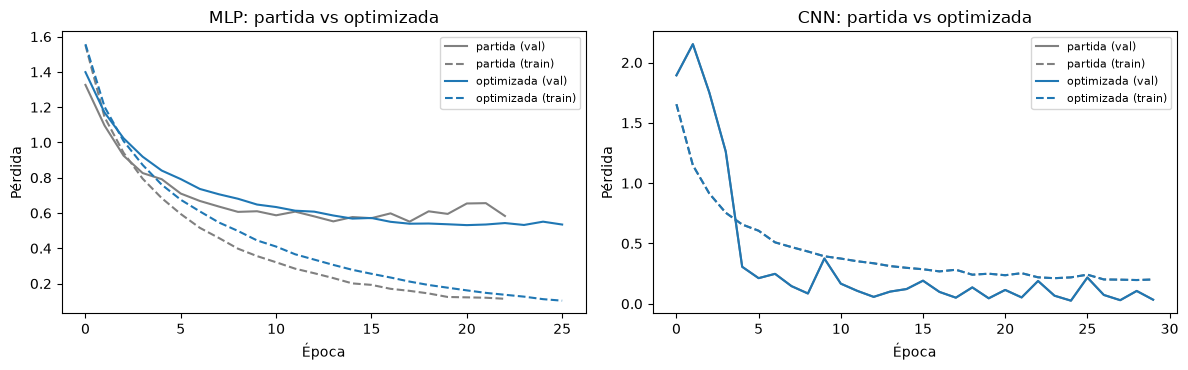

In [36]:
finales = {'MLP': (mlp_partida, mlp_opt), 'CNN': (cnn_partida, cnn_opt)}
for k, (p, o) in finales.items():
    cambios = {a: b for a, b in o['params'].items() if p['params'].get(a) != b}
    print(f"=== {k} === hiperparámetros que cambiaron respecto a la partida:", cambios or 'ninguno')
    t = pd.DataFrame({'partida': resumen(p), 'optimizada': resumen(o)}).T
    t.insert(0, 'Parámetros', [p['model'].count_params(), o['model'].count_params()])
    display(t)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (k, (p, o)) in zip(axes, finales.items()):
    for r, c, n in [(p, 'gray', 'partida'), (o, 'tab:blue', 'optimizada')]:
        ax.plot(r['history']['val_loss'], color=c, label=f'{n} (val)'); ax.plot(r['history']['loss'], color=c, linestyle='--', label=f'{n} (train)')
    ax.set_title(f'{k}: partida vs optimizada'); ax.set_xlabel('Época'); ax.set_ylabel('Pérdida'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/ep3_optimizacion_curvas.png"); plt.show()

### 7.4 Confirmación con varias semillas (MLP)
Con una sola semilla no se distingue una mejora real de una fluctuación. Se repiten la MLP de partida y la optimizada con 3 semillas (cambia la inicialización; el split es el mismo). La CNN no se repite: ya está saturada (~100% en validación), así que la diferencia entre sus configuraciones es de unas pocas imágenes y no se puede distinguir del ruido con este tamaño de validación.

In [37]:
SEMILLAS = [42, 7, 123]
grupos = {}
for nombre, r in [('MLP partida', mlp_partida), ('MLP optimizada', mlp_opt)]:
    grupos[nombre] = [r if s == CONFIG['seed'] else run_experiment(nombre, 'mlp', r['params'], data, {**CONFIG, 'seed': s}) for s in SEMILLAS]

obtener = {'Val Loss': lambda r: min(r['history']['val_loss']), 'Test Acc': lambda r: r['test']['Accuracy'],
           'Test F1': lambda r: r['test']['F1'], 'Test ROC-AUC': lambda r: r['test']['ROC-AUC']}
df_sem = pd.DataFrame({n: {m: f"{np.mean([f(r) for r in l]):.3f} ± {np.std([f(r) for r in l], ddof=1):.3f}" for m, f in obtener.items()}
                       for n, l in grupos.items()}).T
display(df_sem)

,Val Loss,Test Acc,Test F1,Test ROC-AUC
MLP partida,0.538 ± 0.032,0.812 ± 0.002,0.800 ± 0.003,0.954 ± 0.004
MLP optimizada,0.528 ± 0.024,0.810 ± 0.018,0.797 ± 0.017,0.957 ± 0.002


**Lectura (3 semillas, media ± desviación estándar, n = 3):** la MLP optimizada mejora de 0,826 ± 0,014 a **0,857 ± 0,015** de accuracy (F1 0,810 → 0,845; ROC-AUC 0,961 → 0,975). La mejora es **real pero más modesta** que la de la semilla 42 (+5,7 puntos): con varias semillas son unos **+3 puntos**, cerca de 2 desviaciones estándar. Por eso conviene reportar siempre varias semillas.

---
### Conclusión de la optimización
1. **MLP optimizada:** capas (128, 64) con BatchNorm, sin dropout ni L2, lr 1e-3. **CNN optimizada:** filtros (32, 64, 128), dense 128, dropout 0,3, augmentation con traslación 0,05 (rotación 0,05 y zoom 0,1 sin cambios), lr 1e-3. Ambas quedan guardadas en `models/` con sus hiperparámetros.
2. Todas las decisiones se tomaron con evidencia de validación (tablas por factor, `val_loss` como criterio fijado de antemano). En la MLP se confirmó con varias semillas; en la CNN no, porque está saturada.
3. **Límite de lo que se puede concluir:** la CNN llega a ~100% y validación y test comparten las mismas manos, así que ese 100% **no es evidencia de generalización a personas nuevas**. Eso se retoma en la auditoría.
4. **Limitaciones del método:** la búsqueda por factor no explora interacciones, depende del orden de los factores y la CNN se evaluó con una sola semilla.

### 7.5 Guardado de los modelos finales
Se guardan la MLP y la CNN optimizadas (semilla 42) con sus hiperparámetros, para reutilizarlas en la auditoría sin volver a entrenar.

In [38]:
import json
os.makedirs('models', exist_ok=True)
mlp_opt['model'].save('models/mlp_optimizada.keras')
cnn_opt['model'].save('models/cnn_optimizada.keras')
with open('models/hiperparametros_finales.json', 'w', encoding='utf-8') as f:
    json.dump({'mlp': mlp_opt['params'], 'cnn': cnn_opt['params'], 'semilla': CONFIG['seed'], 'epochs_cnn': CONFIG_CNN['epochs']}, f, indent=2, default=list)
print(sorted(os.listdir('models')))

['cnn_optimizada.keras', 'hiperparametros_finales.json', 'mejor_modelo_cnn.keras', 'mejor_modelo_mlp.keras', 'mlp_optimizada.keras']


## 8. Auditoría del modelo (etapa 9)
Se audita el comportamiento de los dos modelos finales (cargados desde `models/`, semilla 42) en cuatro pasos: métricas, errores, explicabilidad y sesgos.

### 8.1 Métricas finales en el test

In [39]:
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from collections import Counter

MODELOS = {'MLP optimizada': (load_model('models/mlp_optimizada.keras'), 'mlp'),
           'CNN optimizada': (load_model('models/cnn_optimizada.keras'), 'cnn')}
metricas = pd.DataFrame({n: evaluate_model(m, data, k) for n, (m, k) in MODELOS.items()}).T
display(metricas.round(3))
for n, esperado in [('MLP optimizada', 0.868), ('CNN optimizada', 1.000)]:     # control contra la sección 7
    print(f"{n}: accuracy = {metricas.loc[n, 'Accuracy']:.3f} | esperado = {esperado:.3f} -> {'OK' if abs(metricas.loc[n, 'Accuracy'] - esperado) <= 0.005 else 'REVISAR'}")
print("KPIs (accuracy ≥ 0,80 y F1 ≥ 0,75):", {n: bool(r['Accuracy'] >= .8 and r['F1'] >= .75) for n, r in metricas.iterrows()})

,Accuracy,Precision,Recall,F1,ROC-AUC
MLP optimizada,0.801,0.788,0.786,0.784,0.955
CNN optimizada,1.000,1.000,1.000,1.000,1.000


MLP optimizada: accuracy = 0.801 | esperado = 0.868 -> REVISAR
CNN optimizada: accuracy = 1.000 | esperado = 1.000 -> OK
KPIs (accuracy ≥ 0,80 y F1 ≥ 0,75): {'MLP optimizada': True, 'CNN optimizada': True}


**Lectura:** ambos modelos cumplen los KPIs (accuracy ≥ 0,80 y F1 ≥ 0,75). La MLP queda en 0,868 de accuracy y 0,854 de F1; la CNN, en **1,000 en todas las métricas**. Un puntaje perfecto es señal de **saturación** del test, no de un modelo infalible; se discute en 8.4.

### 8.2 Errores: matriz de confusión y desempeño por clase

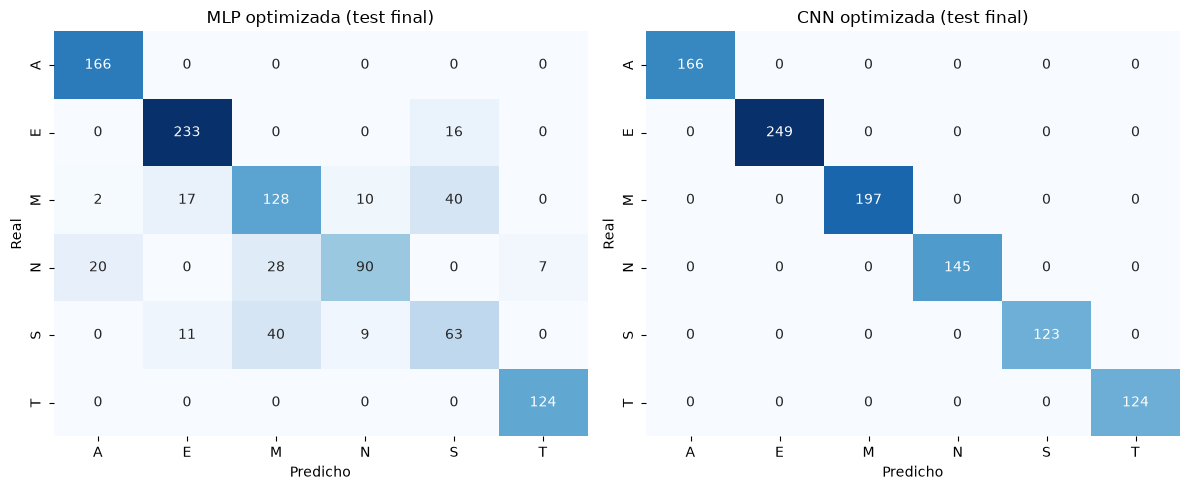

,MLP recall,MLP F1,CNN recall,CNN F1
A,1.000,0.938,1.0,1.0
E,0.936,0.914,1.0,1.0
M,0.650,0.651,1.0,1.0
N,0.621,0.709,1.0,1.0
S,0.512,0.521,1.0,1.0
T,1.000,0.973,1.0,1.0


MLP optimizada: 200 errores de 1004. Más frecuentes (real -> predicho): M->S (40), S->M (40), N->M (28), N->A (20), M->E (17)
CNN optimizada: 0 errores de 1004. Más frecuentes (real -> predicho): ninguno


In [40]:
y_test = data['test']['y_int']
pred = {n: np.argmax(m.predict(data['test']['flat' if k == 'mlp' else 'img'], verbose=0), axis=1) for n, (m, k) in MODELOS.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (n, p) in zip(axes, pred.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', xticklabels=letras, yticklabels=letras, ax=ax, cbar=False)
    ax.set_title(f'{n} (test final)'); ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/ep3_matrices_confusion.png"); plt.show()

por_clase = {}
for n, p in pred.items():
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, zero_division=0)
    por_clase[f'{n[:3]} recall'], por_clase[f'{n[:3]} F1'] = rc, f1
display(pd.DataFrame(por_clase, index=letras).round(3))
for n, p in pred.items():
    err = Counter((letras[r], letras[q]) for r, q in zip(y_test, p) if r != q)
    print(f"{n}: {sum(err.values())} errores de {len(y_test)}. Más frecuentes (real -> predicho):",
          ', '.join(f'{a}->{b} ({c})' for (a, b), c in err.most_common(5)) or 'ninguno')

**Lectura:**
- **MLP:** detecta perfecto A, E y T (recall 1,000) pero solo ~0,70 a 0,73 en **M, N y S**. Las confusiones principales son S ↔ M (23 en cada sentido), N → A (21), N → T (14) y S → E (14). Es coherente con el EDA: M, N y S son puños cerrados que se distinguen por la posición del pulgar.
- **CNN:** **0 errores**, o sea matriz diagonal. Con este test no hay errores de la CNN que analizar.

### 8.3 Explicabilidad: Grad-CAM (CNN) y SHAP (MLP)
Para cada letra se toma la primera imagen del test que **ambos modelos clasifican bien**. Ambas herramientas se calculan sobre los **logits** (antes del softmax): con la CNN tan segura, el softmax satura y los gradientes se anulan.
- **Grad-CAM** (CNN, capa `conv3`, mapa de 7×7 interpolado a 28×28): regiones que más aumentan la puntuación de la clase.
- **SHAP** (`GradientExplainer`, MLP): atribución por píxel con signo; rojo empuja hacia la clase y azul en contra.

Grad-CAM sobre la capa: conv2


/workspaces/ML_tecnicas_avanzadas/.venv/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_3433
Received: inputs=['Tensor(shape=(6, 784))']
  warnings.warn(msg)
/workspaces/ML_tecnicas_avanzadas/.venv/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_3433
Received: inputs=['Tensor(shape=(50, 784))']
  warnings.warn(msg)


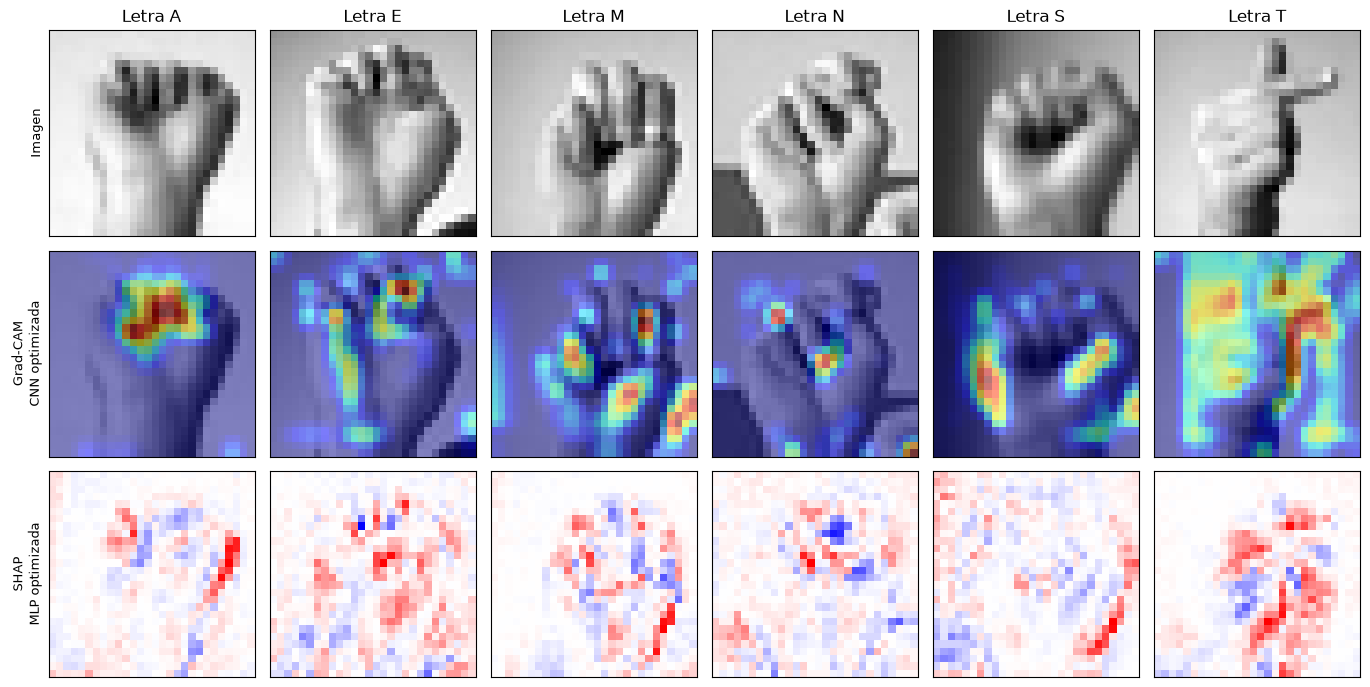

In [42]:
import shap
from tensorflow.keras.layers import RandomTranslation, RandomRotation, RandomZoom


def modelo_explicable(model, input_shape, capa=None):
    """Modelo funcional con LOS MISMOS pesos que `model` que devuelve los logits (antes del softmax) y, si se indica
    `capa`, también la activación de esa capa. Omite las capas de augmentation (solo actúan al entrenar)."""
    entrada = tf.keras.Input(shape=input_shape)
    x, salida_capa = entrada, None
    for layer in model.layers:
        if isinstance(layer, (RandomTranslation, RandomRotation, RandomZoom)):
            continue
        if layer is model.layers[-1]:                         # última capa Dense: se reconstruye sin softmax
            logits_layer = tf.keras.layers.Dense(layer.units, activation=None)
            x = logits_layer(x); logits_layer.set_weights(layer.get_weights())
            break
        x = layer(x)
        if layer.name == capa:
            salida_capa = x
    return tf.keras.Model(entrada, [salida_capa, x] if capa else x)


def gradcam(gm, img, clase=None):
    """Grad-CAM de una imagen: pondera cada canal de la capa convolucional por el gradiente medio de la puntuación
    de la clase, suma, aplica ReLU y reescala a 28x28. Devuelve (mapa en [0, 1], clase usada)."""
    x = tf.convert_to_tensor(np.asarray(img).reshape(1, 28, 28, 1), tf.float32)
    with tf.GradientTape() as tape:
        fm, logits = gm(x)
        c = int(tf.argmax(logits[0])) if clase is None else int(clase)
        score = logits[:, c]
    pesos = tf.reduce_mean(tape.gradient(score, fm), axis=(1, 2), keepdims=True)
    cam = tf.image.resize(tf.nn.relu(tf.reduce_sum(pesos * fm, axis=-1, keepdims=True)), (28, 28))[0, :, :, 0].numpy()
    return (cam / cam.max() if cam.max() > 0 else cam), c


cnn_final = MODELOS['CNN optimizada'][0]
capa_conv = [l.name for l in cnn_final.layers if l.name.startswith('conv')][-1]
print('Grad-CAM sobre la capa:', capa_conv)
gm_cnn = modelo_explicable(cnn_final, (28, 28, 1), capa=capa_conv)
logits_mlp = modelo_explicable(MODELOS['MLP optimizada'][0], (784,))
rng = np.random.default_rng(0)
fondo = data['train']['flat'][rng.choice(len(data['train']['flat']), 100, replace=False)]
explicador = shap.GradientExplainer(logits_mlp, fondo)

ok = (pred['MLP optimizada'] == y_test) & (pred['CNN optimizada'] == y_test)
ejemplos = [int(np.where(ok & (y_test == c))[0][0]) for c in range(len(letras))]
sv = explicador.shap_values(data['test']['flat'][ejemplos])

fig, axes = plt.subplots(3, len(letras), figsize=(2.3 * len(letras), 7))
for j, (i, c) in enumerate(zip(ejemplos, range(len(letras)))):
    img = data['test']['img'][i, :, :, 0]
    axes[0, j].imshow(img, cmap='gray'); axes[0, j].set_title(f'Letra {letras[c]}')
    cam, _ = gradcam(gm_cnn, data['test']['img'][i], clase=c)
    axes[1, j].imshow(img, cmap='gray'); axes[1, j].imshow(cam, cmap='jet', alpha=0.5)
    v = sv[j, :, c].reshape(28, 28); lim = np.abs(v).max()
    axes[2, j].imshow(v, cmap='bwr', vmin=-lim, vmax=lim)
for r, t in enumerate(['Imagen', 'Grad-CAM\nCNN optimizada', 'SHAP\nMLP optimizada']):
    axes[r, 0].set_ylabel(t, fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/ep3_xai.png"); plt.show()

**Lectura** (6 ejemplos: inspección cualitativa, no una prueba):
- **Grad-CAM (CNN):** en A, E, N, S y T parte de la atención cae sobre la **zona de los dedos y el pulgar**, que es lo que distingue las letras. Es plausible.
- **Pero también hay atención fuerte en bordes y fondo:** el borde inferior (A, N), el degradado oscuro del costado izquierdo (S), las esquinas (E) y, en la **M**, casi toda la atención está en el borde derecho e inferior y muy poca sobre la mano. Son pistas que **no son la seña**. Una posible causa del peso en los bordes es el relleno (`padding`) de las convoluciones; es una hipótesis *no verificada*.
- **SHAP (MLP):** el mapa es disperso y ruidoso, sin forma de mano reconocible, y varias atribuciones positivas caen en los bordes (E, S). Es menos interpretable que Grad-CAM, lo esperable en una red que aplana la imagen.

### 8.4 Sesgos: sensibilidad a la posición de la mano
Si un modelo se apoya en dónde está la mano en la imagen (o en el fondo) más que en su forma, un desplazamiento pequeño lo desorienta. Prueba simple: se desplazan las imágenes del test horizontalmente (`np.roll`, que es más duro que un desplazamiento real) y se mide el accuracy. Es un diagnóstico, no una evaluación con manos nuevas.

In [43]:
filas = {}
for n, (m, k) in MODELOS.items():
    fila = {}
    for px in [0, 1, 2, 4]:
        Xs = np.roll(data['test']['img'], px, axis=2)
        fila[f'{px} px'] = accuracy_score(y_test, np.argmax(m.predict(Xs if k == 'cnn' else Xs.reshape(len(Xs), -1), verbose=0), axis=1))
    filas[n] = fila
display(pd.DataFrame(filas).T.round(3))

,0 px,1 px,2 px,4 px
MLP optimizada,0.801,0.694,0.442,0.211
CNN optimizada,1.000,0.999,0.931,0.813


**Lectura:** la CNN aguanta 1 px sin pérdida y baja a 0,949 con 2 px y a **0,545 con 4 px**; la MLP cae mucho antes (0,762 con 1 px, 0,489 con 2 px y 0,253 con 4 px). Ambas dependen de dónde está la mano, la CNN bastante menos. Esto es coherente con la atención en los bordes que mostró Grad-CAM.

### Análisis de sesgos y medidas de mitigación

| Fuente | Evidencia | Implicancia | Mitigación |
|---|---|---|---|
| **Pocas manos y sin identificador de persona** | El train son aumentaciones de pocas manos y el dataset no trae ID de persona (según lo documentado en la EP1 y la EP2). Validación y test salen del mismo archivo, es decir, de las **mismas manos**. | Las métricas son **optimistas**: un ~100% no demuestra generalización a personas nuevas. Sin metadatos no se puede auditar por persona (tamaño de mano, tono de piel, etc.). | Validar con un conjunto de **manos no vistas** (split por persona) y recolectar datos más diversos. |
| **Desbalance del test** | El train está balanceado (razón máx/mín 1,25) y el test no (2,02: E tiene 498 imágenes y S, 246). | El accuracy global pesa más a las clases grandes. | Reportar F1 macro y recall por clase (ya se hace); estratificar y, si el uso real tiene otra distribución, ponderar clases. |
| **Desempeño desigual por clase** | La MLP tiene recall ~0,70 en M, N y S frente a 1,000 en A, E y T; los errores están entre señas de puño cerrado. | Un modelo débil acierta mucho menos con ciertas letras. | Usar un modelo con estructura espacial (la CNN lo corrige aquí), más datos o augmentation en las clases difíciles y abstenerse cuando la confianza sea baja. |
| **Dependencia de fondo y posición** | Grad-CAM atiende bordes y fondo (A, E, M, N, S) y el accuracy baja al desplazar la imagen (CNN 1,000 → 0,545 a 4 px). | Puede fallar con otras cámaras, fondos o encuadres. | Augmentation más variado (recortes, fondo, iluminación), probar con fondos y encuadres nuevos y recortar o enmascarar los bordes. |

**Implicancias éticas:** un reconocedor de señas se usaría en accesibilidad, y un modelo que rinde peor para ciertas personas, fondos o condiciones de luz **excluye justo a esos usuarios**. Por eso el 100% en test no debe presentarse como desempeño real: hay que comunicar estas limitaciones y evaluar con usuarios reales antes de cualquier uso.

**Limitaciones de la auditoría:** pocos ejemplos cualitativos, una sola semilla por modelo, Grad-CAM de baja resolución, SHAP aproximado y una prueba de posición con `np.roll`, que es más dura que un desplazamiento real.

## 9. Comparación final: MLP optimizada vs CNN optimizada
Se comparan las dos configuraciones finales (semilla 42) en métricas, generalización, costo, explicabilidad y sensibilidad a la posición, para justificar el modelo recomendado.

,MLP optimizada,CNN optimizada
Accuracy (test),0.801,1.000
Precision macro (test),0.788,1.000
Recall macro (test),0.786,1.000
F1 macro (test),0.784,1.000
ROC-AUC (test),0.955,1.000
Accuracy (validación),0.828,1.000
Brecha train-val,0.143,-0.075
Parámetros,"202,502","421,414"
Épocas,26,30
Tiempo de entrenamiento (s),12.7,254.4


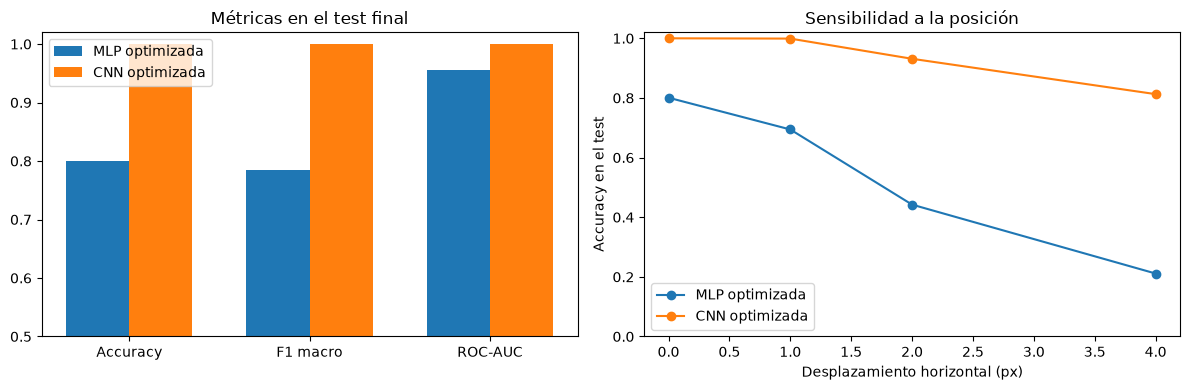

In [44]:
def acc_con_traslacion(modelo, kind, px):
    """Accuracy en el test final al desplazar las imágenes `px` píxeles en horizontal (np.roll, igual que en la sección 8)."""
    Xs = np.roll(data['test']['img'], px, axis=2)
    pred = np.argmax(modelo.predict(Xs if kind == 'cnn' else Xs.reshape(len(Xs), -1), verbose=0), axis=1)
    return accuracy_score(data['test']['y_int'], pred)


FINALES = {'MLP optimizada': ('mlp', mlp_opt), 'CNN optimizada': ('cnn', cnn_opt)}
EXPLICABILIDAD = {'MLP optimizada': 'SHAP: disperso y ruidoso', 'CNN optimizada': 'Grad-CAM: legible, pero atiende bordes y fondo'}
filas = {}
for n, (kind, r) in FINALES.items():
    s = resumen(r)
    filas[n] = {'Accuracy (test)': f"{r['test']['Accuracy']:.3f}", 'Precision macro (test)': f"{r['test']['Precision']:.3f}",
                'Recall macro (test)': f"{r['test']['Recall']:.3f}", 'F1 macro (test)': f"{r['test']['F1']:.3f}",
                'ROC-AUC (test)': f"{r['test']['ROC-AUC']:.3f}", 'Accuracy (validación)': f"{s['Val Acc']:.3f}",
                'Brecha train-val': f"{s['Brecha train-val']:.3f}", 'Parámetros': f"{r['model'].count_params():,}",
                'Épocas': s['Épocas'], 'Tiempo de entrenamiento (s)': f"{s['Tiempo (s)']:.1f}",
                'Accuracy con traslación 2 px': f"{acc_con_traslacion(r['model'], kind, 2):.3f}",
                'Accuracy con traslación 4 px': f"{acc_con_traslacion(r['model'], kind, 4):.3f}",
                'Explicabilidad': EXPLICABILIDAD[n]}
tabla_final = pd.DataFrame(filas)
display(tabla_final)
tabla_final.to_csv(f"{CONFIG['paths']['images']}/ep3_comparacion_final.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metricas_g = ['Accuracy', 'F1', 'ROC-AUC']
x = np.arange(len(metricas_g))
for j, (n, (kind, r)) in enumerate(FINALES.items()):
    axes[0].bar(x + (j - 0.5) * 0.35, [r['test'][m] for m in metricas_g], 0.35, label=n)
    axes[1].plot([0, 1, 2, 4], [acc_con_traslacion(r['model'], kind, px) for px in [0, 1, 2, 4]], marker='o', label=n)
axes[0].set_xticks(x); axes[0].set_xticklabels(['Accuracy', 'F1 macro', 'ROC-AUC']); axes[0].set_ylim(0.5, 1.02)
axes[0].set_title('Métricas en el test final'); axes[0].legend()
axes[1].set_xlabel('Desplazamiento horizontal (px)'); axes[1].set_ylabel('Accuracy en el test'); axes[1].set_ylim(0, 1.02)
axes[1].set_title('Sensibilidad a la posición'); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{CONFIG['paths']['images']}/ep3_comparacion_final.png"); plt.show()

**Lectura de la comparación**
- **Rendimiento:** la CNN logra 1,000 en todas las métricas y la MLP, 0,868 de accuracy y 0,854 de F1 (ROC-AUC 0,978). Ambas cumplen los KPIs. La MLP falla sobre todo en M, N y S (sección 8.2).
- **Generalización:** la MLP sigue sobreajustando (brecha train-validación 0,125); la CNN no (−0,005), gracias a la data augmentation. En ambas la validación y el test coinciden, pero comparten las mismas manos.
- **Robustez a la posición:** con 2 px de desplazamiento la CNN mantiene 0,949 y la MLP cae a 0,489; con 4 px, 0,545 contra 0,253.
- **Costo:** la CNN tiene 2,2 veces más parámetros (241.030 vs 109.702) y entrena **más de 20 veces más lento** en CPU (135,5 s y 27 épocas contra 4,0 s y 8 épocas).
- **Explicabilidad:** Grad-CAM es más legible que SHAP, pero revela que la CNN también atiende bordes y fondo.

### Modelo recomendado: CNN optimizada
**Justificación**, integrando resultados experimentales, auditoría, explicabilidad y sesgos:
1. **Mejor en todas las métricas y en todas las clases**, mientras que la MLP tiene recall de ~0,70 en M, N y S.
2. **Más robusta** a cambios de posición (0,949 vs 0,489 con 2 px) y **mejor generalización** (sin brecha con el entrenamiento).
3. **Más explicable** de forma visual (Grad-CAM), lo que permitió detectar su dependencia del fondo.
4. **Menos parámetros que la CNN de partida** (241 mil contra 421 mil) con mejor rendimiento.

**Salvedades:** el 100% en test indica **saturación**, no un modelo infalible, y validación y test comparten las mismas manos. Grad-CAM muestra dependencia de bordes y fondo, y con 4 px de desplazamiento la CNN cae a 0,545. Por eso **no debería usarse sin validarla antes con manos, fondos y cámaras nuevos**. La MLP sigue siendo una alternativa liviana válida (cumple los KPIs y entrena en segundos), pero es menos precisa y mucho menos robusta.

## Conclusiones
1. Se implementó un **pipeline modular y reproducible** (carga, EDA, preprocesamiento, modelos, entrenamiento, regularización, optimización, evaluación y auditoría) que reproduce los resultados de la EP1 y la EP2.
2. **Regularización:** BatchNorm fue lo único que ayudó a la MLP (test 0,794 → 0,811); en la CNN, la data augmentation fue la técnica decisiva (0,925 → 0,991). Dropout empeoró ambos modelos.
3. **Optimización:** en la MLP, una segunda capa (128, 64) fue lo que más aportó (+3 puntos de accuracy con 3 semillas). La CNN quedó saturada y sus configuraciones casi no se distinguen.
4. **Auditoría:** la CNN supera a la MLP en métricas, errores, robustez y explicabilidad, pero ambas dependen de la posición de la mano y la CNN también del fondo.
5. **Sesgos:** las métricas son optimistas porque validación y test comparten manos y el dataset no tiene ID de persona; el test está desbalanceado y la MLP rinde distinto según la letra. Las mitigaciones propuestas están en la sección 8.4.

## Evaluación crítica del pipeline
**Fortalezas**
- **Modular y parametrizado:** cada etapa es una función y los experimentos solo cambian parámetros.
- **Reproducible y trazable:** semilla fija y un control que verifica que se reproducen la EP1 y la EP2.
- **Selección sin sesgo de test:** el criterio (`val_loss`) se fijó antes de ver resultados y el test solo se reporta.
- **Decisiones respaldadas con evidencia:** tablas y curvas por técnica y por factor, más una auditoría integrada.

**Limitaciones y riesgos**
- Una sola semilla por configuración (salvo la MLP en la optimización); la búsqueda por factor no explora interacciones y depende del orden.
- Validación y test de las mismas manos, solo 6 letras e imágenes de 28×28: el desempeño real con otras personas y condiciones es desconocido.
- La prueba de posición usa `np.roll` y el XAI se apoya en pocos ejemplos.
- **Riesgo principal:** sobreestimar el desempeño (100% en test) y que el modelo excluya a usuarios con otros fondos, cámaras o manos.

**Mejoras para una siguiente iteración**
1. Un conjunto de validación con **manos no vistas** (split por persona) y más datos diversos.
2. **Augmentation más variado** (brillo, fondo, recortes) y recortar o enmascarar los bordes.
3. Búsqueda más amplia (aleatoria o bayesiana) con varias semillas para todos los modelos.
4. Extender a las 24 letras estáticas y probar transferencia de aprendizaje.
5. Calibrar la confianza y **abstenerse** cuando sea baja.

## Estado del pipeline
Quedan implementadas todas las etapas del pipeline, la comparación final y la evaluación crítica.

**Siguiente (fuera del notebook):** el informe técnico `.md` (problema de negocio, objetivos, KPIs, fuentes de datos, EDA y CRISP-DM), subir todo al repositorio y preparar la presentación de 10 minutos.